# Regression Tree — Both Pooling (fac=1, amb=1)

How much variance in T1 mortality can we explain with the uncertainties?
Cross-validated R² at different tree depths.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import cross_val_score

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
sub = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
print(f"Policy: Both Pooling (fac=1, amb=1), {len(sub)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOME = "death_rate_T1_BCAS"

X = sub[UNCERTAINTIES].astype(float)
y = sub[OUTCOME].values
print(f"Outcome range: {y.min():.4f} to {y.max():.4f}, mean={y.mean():.4f}")


Policy: Both Pooling (fac=1, amb=1), 24576 runs
Outcome range: 0.0000 to 1.0000, mean=0.0856


## Cross-Validated R² vs Tree Depth


depth= 1: R²=0.1300 ± 0.0129


depth= 2: R²=0.2749 ± 0.0129


depth= 3: R²=0.3835 ± 0.0228


depth= 4: R²=0.4946 ± 0.0316


depth= 5: R²=0.5963 ± 0.0319


...

depth=11: R²=0.7129 ± 0.0223


depth=12: R²=0.7131 ± 0.0213


depth=13: R²=0.7135 ± 0.0212


depth=14: R²=0.7135 ± 0.0213


depth=15: R²=0.7135 ± 0.0213


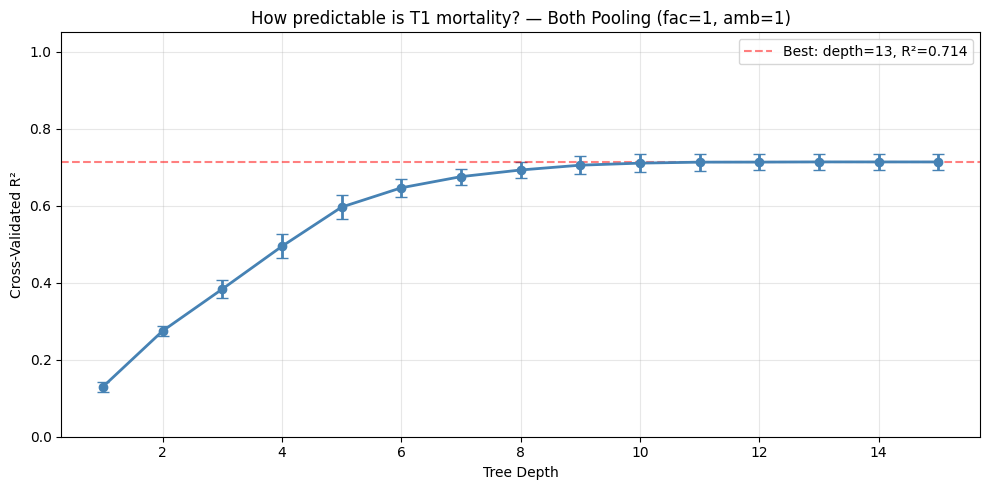


Best depth: 13, R² = 0.7135


In [2]:
depths = list(range(1, 16))
cv_means = []
cv_stds = []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42)
    scores = cross_val_score(tree, X, y, cv=10, scoring="r2")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"depth={d:2d}: R²={scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(depths, cv_means, yerr=cv_stds, capsize=4, marker="o", color="steelblue", linewidth=2)
ax.set_xlabel("Tree Depth")
ax.set_ylabel("Cross-Validated R²")
ax.set_title("How predictable is T1 mortality? — Both Pooling (fac=1, amb=1)")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)

best_d = depths[np.argmax(cv_means)]
best_r2 = max(cv_means)
ax.axhline(best_r2, color="red", linestyle="--", alpha=0.5, label=f"Best: depth={best_d}, R²={best_r2:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nBest depth: {best_d}, R² = {best_r2:.4f}")


## Best Tree Visualization


Train R² = 0.5182


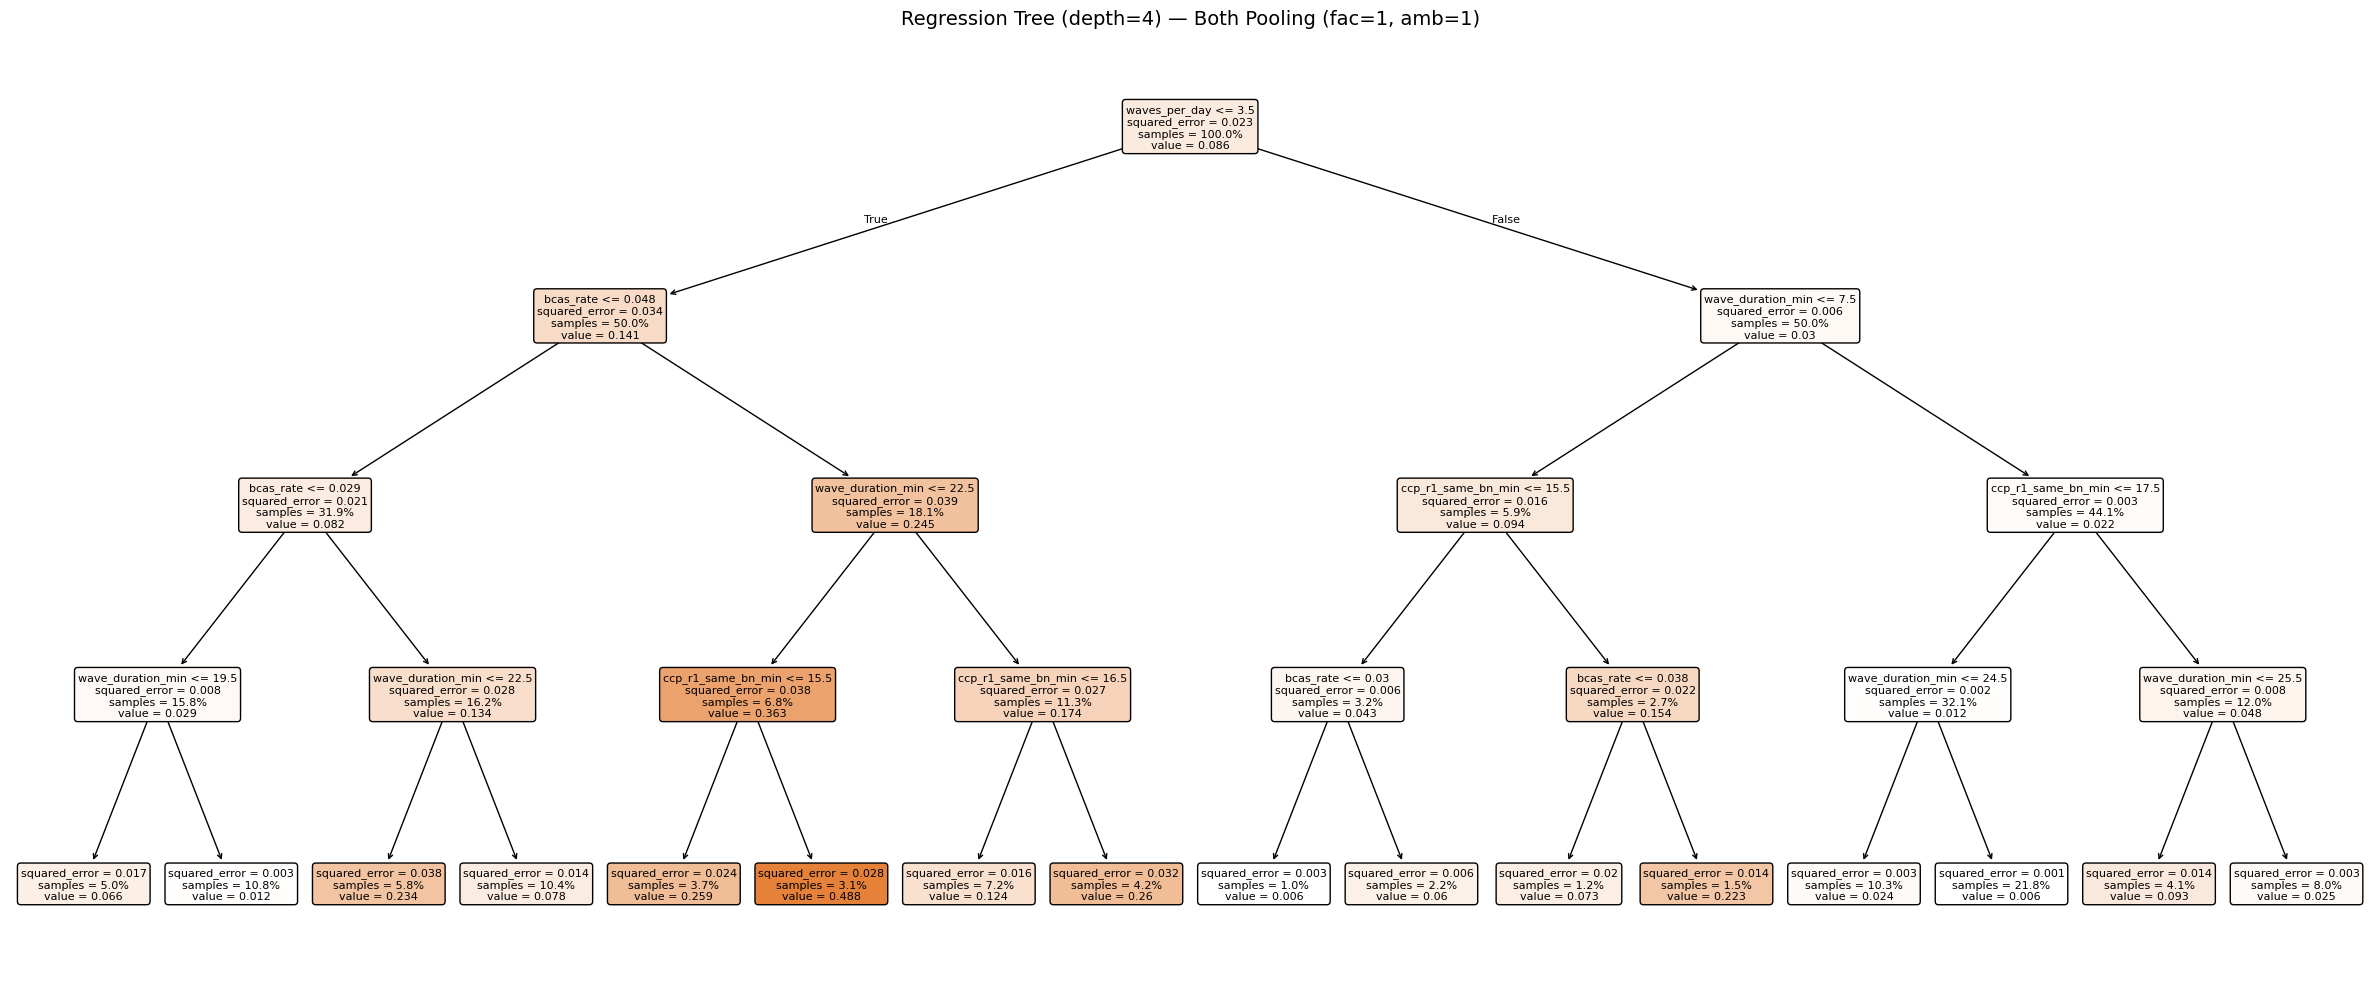

In [3]:
best_tree = DecisionTreeRegressor(max_depth=min(best_d, 4), min_samples_leaf=20, random_state=42)
best_tree.fit(X, y)
print(f"Train R² = {best_tree.score(X, y):.4f}")

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(best_tree, feature_names=UNCERTAINTIES, filled=True, rounded=True,
          fontsize=8, ax=ax, proportion=True)
ax.set_title(f"Regression Tree (depth={min(best_d, 4)}) — Both Pooling (fac=1, amb=1)", fontsize=14)
plt.tight_layout()
plt.show()


## Feature Importance


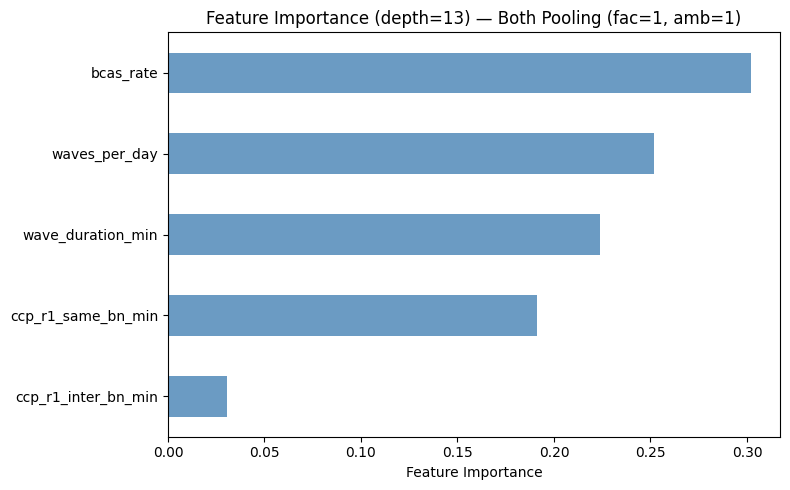

bcas_rate             0.3020
waves_per_day         0.2521
wave_duration_min     0.2240
ccp_r1_same_bn_min    0.1911
ccp_r1_inter_bn_min   0.0308


In [4]:
best_tree_full = DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42)
best_tree_full.fit(X, y)

imp = pd.Series(best_tree_full.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="steelblue", alpha=0.8)
ax.set_xlabel("Feature Importance")
ax.set_title(f"Feature Importance (depth={best_d}) — Both Pooling (fac=1, amb=1)")
plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).to_string(float_format="%.4f"))


## Predicted vs Actual


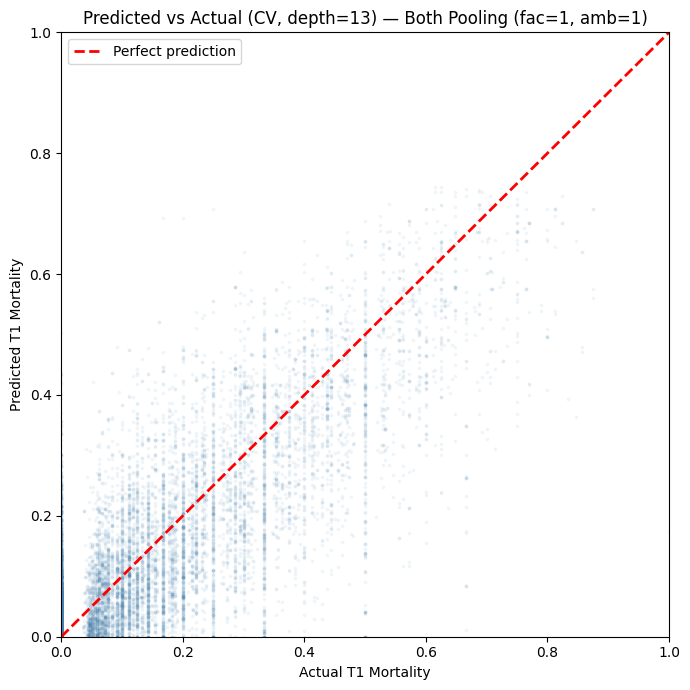

MAE: 0.0455
RMSE: 0.0805


In [5]:
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42), X, y, cv=10)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y, y_pred, alpha=0.05, s=3, color="steelblue")
ax.plot([0, 1], [0, 1], "r--", linewidth=2, label="Perfect prediction")
ax.set_xlabel("Actual T1 Mortality")
ax.set_ylabel("Predicted T1 Mortality")
ax.set_title(f"Predicted vs Actual (CV, depth={best_d}) — Both Pooling (fac=1, amb=1)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

residuals = y - y_pred
print(f"MAE: {np.abs(residuals).mean():.4f}")
print(f"RMSE: {np.sqrt((residuals**2).mean()):.4f}")
